# Strefy zarządzania 2D K-Means (`NDVI z-score` + `awc_mm_per_m` w siatce H3 poz. 10)

Pipeline treningowy i walidacyjny (Train 2023–2024 vs Test 2025):
1. **Dane treningowe (2023–2024)** i **testowe (2025)**: do 8 scen Sentinel-2 na sezon wegetacyjny (`03-01` .. `10-31`).
2. **Cechy**: pola `>= 3 ha`, bufor wewnętrzny `10 m`, z-score NDVI per scena/pole + mediana czasowa oraz natywna jednostka gleby `awc_mm_per_m` w komórkach **H3 poziomu 10** (`~250 m`, **bez agregacji do pola**).
3. **Model 2D K-Means** (`[ndvi_z, awc_z]`, `k = 3`: `1 = slaba`, `2 = srednia`, `3 = mocna`) uczony wyłącznie na latach **2023–2024**, zapisywany do `.joblib`.
4. **Moduły testowania modelu** na niewidzianym roku **2025**: metryki jakości klasteryzacji, test generalizacji i stabilności międzyrocznej, wykresy diagnostyczne oraz porównanie przestrzenne pól.

In [1]:
import os
from pathlib import Path
from ndvi_kmeans import (
    ZONE_LABELS_3,
    build_feature_matrix,
    extract_field_features,
    fit_ordered_kmeans,
    load_kmeans_metadata,
    load_kmeans_model,
    majority_filter_zones,
    process_fields_ndvi_kmeans,
    train_kmeans_model,
)
os.environ.setdefault("AWS_NO_SIGN_REQUEST", "YES")
from ndvi_ndmi_downloader import download_clip_sentinel_ndvi_ndmi
from rasterio.enums import Resampling
from rasterio.warp import reproject
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    cohen_kappa_score,
    confusion_matrix,
    davies_bouldin_score,
    silhouette_score,
)
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd

BOUNDARY_FILE = Path("data/fields/lowicki_fields_crops.geojson")
SOIL_SOURCE = Path("data/soil/field_soil_h3_cells.parquet")

TRAIN_NDVI_DIR = Path("data/satellite/lowicki_train_2023_2024")
TEST_NDVI_DIR = Path("data/satellite/lowicki_test_2025")
TRAIN_WINDOWS = [("2023-03-01", "2023-10-31"), ("2024-03-01", "2024-10-31")]
TEST_WINDOW = ("2025-03-01", "2025-10-31")
N_SCENES_PER_SEASON = 8

OUT_DIR = Path("data/zones")
TRAIN_OUT_DIR = OUT_DIR / "train_2023_2024"
TEST_OUT_DIR = OUT_DIR / "test_2025"
MODEL_PATH = OUT_DIR / "ndvi_awc_kmeans_model.joblib"
N_CLUSTERS = 3
AWC_WEIGHT = 0.75

## 1. Pobranie i weryfikacja danych satelitarnych (Train 2023–2024 vs Test 2025)

In [2]:
TRAIN_NDVI_DIR.mkdir(parents=True, exist_ok=True)
TEST_NDVI_DIR.mkdir(parents=True, exist_ok=True)

for start_date, end_date in TRAIN_WINDOWS:
    yr = start_date[:4]
    cached = sorted(TRAIN_NDVI_DIR.glob(f"ndvi_ndmi_{yr}-*.tif"))
    if cached:
        print(f"Znaleziono {len(cached)} zcache'owanych scen treningowych dla roku {yr} — pomijam pobieranie.")
    else:
        download_clip_sentinel_ndvi_ndmi(
            boundary_file=BOUNDARY_FILE,
            start_date=start_date,
            end_date=end_date,
            out_dir=TRAIN_NDVI_DIR,
            max_cc=20,
            n_scenes=N_SCENES_PER_SEASON,
            max_missing_ratio=0.3,
        )

test_start, test_end = TEST_WINDOW
test_yr = test_start[:4]
cached_test = sorted(TEST_NDVI_DIR.glob(f"ndvi_ndmi_{test_yr}-*.tif"))
if cached_test:
    print(f"Znaleziono {len(cached_test)} zcache'owanych scen testowych dla roku {test_yr} — pomijam pobieranie.")
else:
    print(f"Pobieranie danych testowych: {test_start} .. {test_end}")
    download_clip_sentinel_ndvi_ndmi(
        boundary_file=BOUNDARY_FILE,
        start_date=test_start,
        end_date=test_end,
        out_dir=TEST_NDVI_DIR,
        max_cc=20,
        n_scenes=N_SCENES_PER_SEASON,
        max_missing_ratio=0.3,
    )

train_tifs = sorted(list(TRAIN_NDVI_DIR.glob("*.tif")) + list(TRAIN_NDVI_DIR.glob("*.tiff")))
test_tifs = sorted(list(TEST_NDVI_DIR.glob("*.tif")) + list(TEST_NDVI_DIR.glob("*.tiff")))
datasets = {"train": train_tifs, "test": test_tifs}

summary_rows = []
for split_name, paths in [("Train (2023-2024)", datasets["train"]), ("Test (2025)", datasets["test"])]:
    by_year = {}
    for p in paths:
        date_str = p.stem.split("_")[2]
        by_year.setdefault(date_str[:4], []).append(date_str)
    for yr, dates in sorted(by_year.items()):
        dates_sorted = sorted(dates)
        summary_rows.append({
            "zbior": split_name,
            "rok": yr,
            "liczba_scen": len(dates_sorted),
            "pierwsza_scena": dates_sorted[0],
            "ostatnia_scena": dates_sorted[-1],
        })

print(f"Zrodlo gleby H3 L10: {SOIL_SOURCE} (istnieje: {SOIL_SOURCE.exists()})")
display(pd.DataFrame(summary_rows))

Znaleziono 8 zcache'owanych scen treningowych dla roku 2023 — pomijam pobieranie.
Znaleziono 8 zcache'owanych scen treningowych dla roku 2024 — pomijam pobieranie.
Znaleziono 8 zcache'owanych scen testowych dla roku 2025 — pomijam pobieranie.
Zrodlo gleby H3 L10: data\soil\field_soil_h3_cells.parquet (istnieje: True)


,zbior,rok,liczba_scen,pierwsza_scena,ostatnia_scena
0,Train (2023-2024),2023,8,2023-04-22,2023-09-29
1,Train (2023-2024),2024,8,2024-04-11,2024-10-18
2,Test (2025),2025,8,2025-03-19,2025-09-25


## 2. Trening modelu 2D K-Means na danych treningowych (2023–2024)

In [3]:
model, meta = train_kmeans_model(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=TRAIN_NDVI_DIR,
    model_path=MODEL_PATH,
    n_clusters=N_CLUSTERS,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    soil_source=SOIL_SOURCE,
    awc_weight=AWC_WEIGHT,
    awc_norm="within_field",
    awc_min_std=2.5,
)
meta

Pominieto 14 pol bez wystarczajacych pikseli NDVI.


{'n_fields': 2347,
 'n_pixels': 1097393,
 'n_scenes': 16,
 'inner_buffer_m': 10.0,
 'min_area_ha': 3.0,
 'random_state': 42,
 'zone_empirical_means': {'1': {'ndvi_z': -0.5512, 'awc_z': -0.5049},
  '2': {'ndvi_z': 0.1156, 'awc_z': 0.0616},
  '3': {'ndvi_z': 0.8734, 'awc_z': 0.7662}},
 'awc_weight': 0.75,
 'awc_unit': 'h3_index_10',
 'awc_norm': 'within_field',
 'awc_min_std': 2.5}

## 3. Wyznaczenie stref zarządzania dla zbioru treningowego (2023–2024) i testowego (2025)

In [4]:
train_zones_gdf = process_fields_ndvi_kmeans(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=TRAIN_NDVI_DIR,
    out_dir=TRAIN_OUT_DIR,
    model_path=MODEL_PATH,
    load_model=True,
    soil_source=SOIL_SOURCE,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    min_zone_area_ha=0.15,
    apply_majority_filter=True,
    save_rasters=False,
)

test_zones_gdf = process_fields_ndvi_kmeans(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=TEST_NDVI_DIR,
    out_dir=TEST_OUT_DIR,
    model_path=MODEL_PATH,
    load_model=True,
    soil_source=SOIL_SOURCE,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    min_zone_area_ha=0.15,
    apply_majority_filter=True,
    save_rasters=False,
)

for title, gdf_res in [("Train (2023-2024)", train_zones_gdf), ("Test (2025)", test_zones_gdf)]:
    print(f"\n=== Podsumowanie wektorowych stref: {title} ===")
    display(
        gdf_res.groupby(["zone", "zone_label"])
        .agg(
            polygons=("area_ha", "count"),
            total_area_ha=("area_ha", "sum"),
            mean_ndvi_z=("ndvi_z", "mean"),
            mean_awc_mm_per_m=("awc_mm_per_m", "mean"),
        )
        .round(3)
    )

Pominieto 14 pol bez wystarczajacych pikseli NDVI.
Pominieto 14 pol bez wystarczajacych pikseli NDVI.

=== Podsumowanie wektorowych stref: Train (2023-2024) ===


,,polygons,total_area_ha,mean_ndvi_z,mean_awc_mm_per_m
zone,zone_label,,,,
1,slaba,5026,3361.115,-0.476,94.234
2,srednia,7177,5968.644,0.112,95.537
3,mocna,2981,1637.096,0.790,98.314



=== Podsumowanie wektorowych stref: Test (2025) ===


,,polygons,total_area_ha,mean_ndvi_z,mean_awc_mm_per_m
zone,zone_label,,,,
1,slaba,5084,3296.496,-0.469,94.284
2,srednia,7280,6132.979,0.101,95.567
3,mocna,2953,1537.383,0.760,98.383


## 4. Moduły testowania i walidacji modelu

- **Moduł 1**: Nienadzorowane metryki jakości klasteryzacji (`Silhouette`, `Davies-Bouldin`, `Calinski-Harabasz`, inercja/piksel) oraz kontrola monotoniczności cech agronomicznych w strefach `1 < 2 < 3`.
- **Moduł 2**: Test generalizacji granic decyzyjnych (zamrożony model 2023–2024 vs niezależny refit na 2025) oraz stabilność międzyroczna stref piksel-po-pikselu (`Agreement %`, `Cohen's kappa`, `Weighted kappa`, `ARI`, macierz przejść).
- **Moduł 3**: Wykresy diagnostyczne (macierz przejść, przestrzeń cech `[ndvi_z, awc_z]`, udział powierzchni stref, histogram stabilności pól).
- **Moduł 4**: Przestrzenne porównanie stref Train (`2023–2024`) vs Test (`2025`) oraz mapy zgodności dla wybranego pola.

In [5]:
# MODUŁ 1: Ewaluacja na zbiorze treningowym (2023-2024) i testowym (2025)
def eval_split(ndvi_dir):
    model, model_meta = load_kmeans_model(MODEL_PATH), load_kmeans_metadata(MODEL_PATH)
    awc_w = float(model_meta.get("awc_weight", AWC_WEIGHT))
    raster_paths, _, features, _ = extract_field_features(
        BOUNDARY_FILE, ndvi_dir, inner_buffer_m=10.0, min_area_ha=3.0,
        soil_source=SOIL_SOURCE, awc_norm="within_field", awc_min_std=2.5,
    )
    X_l, raw_l, filt_l, awc_l, fpreds, all_z = [], [], [], [], {}, 0
    for fid, mz, ag, az, meta in features:
        Xf, vm = build_feature_matrix(mz, awc_z=az)
        if Xf.shape[0] == 0:
            continue
        rp = (model.predict(Xf) + 1).astype(np.uint8)
        zmap = np.zeros(mz.shape, dtype=np.uint8)
        zmap[vm] = rp
        zmap = majority_filter_zones(zmap, size=3)
        fp = zmap[vm].astype(np.uint8)
        all_z += int(np.unique(fp[fp > 0]).size == N_CLUSTERS)
        X_l.append(Xf); raw_l.append(rp); filt_l.append(fp); awc_l.append(ag[vm].astype(np.float32))
        fpreds[fid] = {"zones": zmap, "ndvi_z": mz, "awc_grid": ag, "meta": meta}

    X_all, y_raw, y_filt, awc_raw = np.vstack(X_l), np.concatenate(raw_l), np.concatenate(filt_l), np.concatenate(awc_l)
    zs = pd.DataFrame([
        {
            "zone": z, "zone_label": ZONE_LABELS_3[z], "n_pixels": int(np.sum(y_filt == z)),
            "share_pct": round(100.0 * float(np.mean(y_filt == z)), 2),
            "mean_ndvi_z": float(np.mean(X_all[y_filt == z, 0])),
            "mean_awc_z": float(np.mean(X_all[y_filt == z, 1])),
            "mean_awc_mm_per_m": float(np.nanmean(awc_raw[y_filt == z])),
        }
        for z in range(1, N_CLUSTERS + 1) if np.any(y_filt == z)
    ])
    s1d = (X_all[:, 0] + awc_w * X_all[:, 1]).reshape(-1, 1)
    ss = min(20_000, len(X_all))
    metrics = {
        "n_scenes": len(raster_paths), "n_fields": len(fpreds), "n_pixels": len(X_all),
        "silhouette_2d": float(silhouette_score(X_all, y_raw, sample_size=ss, random_state=42)),
        "davies_bouldin_2d": float(davies_bouldin_score(X_all, y_raw)),
        "calinski_harabasz_2d": float(calinski_harabasz_score(X_all, y_raw)),
        "silhouette_1d": float(silhouette_score(s1d, y_raw, sample_size=ss, random_state=42)),
        "inertia_per_pixel": float(np.mean(np.sum((X_all - model.cluster_centers_[y_raw - 1]) ** 2, axis=1))),
        "pct_fields_all_zones": round(100.0 * all_z / max(1, len(fpreds)), 2),
        "filter_changed_pct": round(100.0 * float(np.mean(y_raw != y_filt)), 2),
        "monotonic_ndvi_z": bool(len(zs) == N_CLUSTERS and np.all(np.diff(zs["mean_ndvi_z"]) > 0)),
        "monotonic_awc_z": bool(len(zs) == N_CLUSTERS and np.all(np.diff(zs["mean_awc_z"]) > 0)),
        "monotonic_awc_raw": bool(len(zs) == N_CLUSTERS and np.all(np.diff(zs["mean_awc_mm_per_m"]) > 0)),
    }
    idx = np.random.default_rng(42).choice(len(X_all), size=ss, replace=False)
    sdf = pd.DataFrame({"ndvi_z": X_all[idx, 0], "awc_z": X_all[idx, 1], "zone_raw": y_raw[idx], "awc_mm_per_m": awc_raw[idx]})
    return {"model": model, "X": X_all, "labels": y_raw, "metrics": metrics, "zone_summary_df": zs, "sample_df": sdf, "field_predictions": fpreds}


def align_pair(tr_p, te_p):
    tz, tn, tm, ez, en, em = tr_p["zones"], tr_p["ndvi_z"], tr_p["meta"], te_p["zones"], te_p["ndvi_z"], te_p["meta"]
    ag = tr_p["awc_grid"] if tr_p.get("awc_grid") is not None else te_p.get("awc_grid")
    if tm["crs"] == em["crs"] and tm["transform"] == em["transform"] and tz.shape == ez.shape:
        return tz, ez, tn, en, ag
    def _rp(arr, nodata):
        dst = np.full((tm["height"], tm["width"]), nodata, dtype=arr.dtype)
        reproject(arr, dst, src_transform=em["transform"], src_crs=em["crs"], dst_transform=tm["transform"], dst_crs=tm["crs"], resampling=Resampling.nearest, src_nodata=nodata, dst_nodata=nodata)
        return dst
    return tz, _rp(ez, 0), tn, _rp(en.astype(np.float32), np.nan), ag


train_eval, test_eval = eval_split(TRAIN_NDVI_DIR), eval_split(TEST_NDVI_DIR)
m_te = test_eval["metrics"]
print(f"Test 2025 (2D) -> Silhouette: {m_te['silhouette_2d']:.3f} | Davies-Bouldin: {m_te['davies_bouldin_2d']:.3f} | Calinski-Harabasz: {m_te['calinski_harabasz_2d']:.1f}")

cmp_df = pd.DataFrame([
    {"metric": k, "train_2023_2024": train_eval["metrics"][k], "test_2025": test_eval["metrics"][k]}
    for k in train_eval["metrics"]
])
print("\n=== Porownanie metryk jakosci: Train (2023-2024) vs Test (2025) ===")
display(cmp_df)

for label_set, ev in [("Train (2023-2024)", train_eval), ("Test (2025)", test_eval)]:
    m = ev["metrics"]
    print(f"{label_set}: monotonicznosc ndvi_z={m['monotonic_ndvi_z']}, awc_z={m['monotonic_awc_z']}, awc_mm_per_m={m['monotonic_awc_raw']} | pola z 3 strefami: {m['pct_fields_all_zones']:.1f}%")
    display(ev["zone_summary_df"].round(3))

Pominieto 14 pol bez wystarczajacych pikseli NDVI.
Pominieto 14 pol bez wystarczajacych pikseli NDVI.
Test 2025 (2D) -> Silhouette: 0.244 | Davies-Bouldin: 1.421 | Calinski-Harabasz: 339881.4

=== Porownanie metryk jakosci: Train (2023-2024) vs Test (2025) ===


,metric,train_2023_2024,test_2025
0,n_scenes,16,8
1,n_fields,2347,2347
2,n_pixels,1097393,1097393
3,silhouette_2d,0.23735,0.244124
4,davies_bouldin_2d,1.442754,1.421155
5,calinski_harabasz_2d,337249.104181,339881.402252
6,silhouette_1d,0.515689,0.516391
7,inertia_per_pixel,0.667091,0.641425
8,pct_fields_all_zones,94.72,94.93
9,filter_changed_pct,5.76,6.27


Train (2023-2024): monotonicznosc ndvi_z=True, awc_z=True, awc_mm_per_m=True | pola z 3 strefami: 94.7%


,zone,zone_label,n_pixels,share_pct,mean_ndvi_z,mean_awc_z,mean_awc_mm_per_m
0,1,slaba,340815,31.06,-0.537,-0.512,93.312
1,2,srednia,581228,52.96,0.112,0.065,94.822
2,3,mocna,175350,15.98,0.867,0.779,97.882


Test (2025): monotonicznosc ndvi_z=True, awc_z=True, awc_mm_per_m=True | pola z 3 strefami: 94.9%


,zone,zone_label,n_pixels,share_pct,mean_ndvi_z,mean_awc_z,mean_awc_mm_per_m
0,1,slaba,334464,30.48,-0.526,-0.529,93.536
1,2,srednia,596938,54.40,0.106,0.070,94.538
2,3,mocna,165991,15.13,0.820,0.815,98.563


In [6]:
# MODUŁ 2: Generalizacja granic decyzyjnych i stabilnosc czasowa (2023-2024 vs 2025)
refit = fit_ordered_kmeans(test_eval["X"], n_clusters=N_CLUSTERS, random_state=42, awc_weight=AWC_WEIGHT)
shifts = np.linalg.norm(train_eval["model"].cluster_centers_ - refit.cluster_centers_, axis=1)
gen = {
    "frozen_vs_refit_agreement_pct": round(100.0 * float(np.mean(test_eval["labels"] == (refit.labels_ + 1))), 2),
    "frozen_vs_refit_kappa": round(float(cohen_kappa_score(test_eval["labels"], refit.labels_ + 1)), 4),
    "max_centroid_shift_l2": round(float(np.max(shifts)), 4),
    "centroid_shifts_l2": [round(float(v), 4) for v in shifts],
}

y_tr_l, y_te_l, n_tr_l, n_te_l, pf_rows = [], [], [], [], []
for fid in sorted(set(train_eval["field_predictions"]) & set(test_eval["field_predictions"])):
    trz, tez, trn, ten, _ = align_pair(train_eval["field_predictions"][fid], test_eval["field_predictions"][fid])
    ov = (trz > 0) & (tez > 0)
    if not np.any(ov):
        continue
    yt, yp, nt, np_ = trz[ov].astype(np.int16), tez[ov].astype(np.int16), trn[ov], ten[ov]
    d = np.abs(yt - yp)
    corr = float(np.corrcoef(nt, np_)[0, 1]) if yt.size >= 3 and np.std(nt) > 1e-6 and np.std(np_) > 1e-6 else np.nan
    pf_rows.append({"field_id": fid, "n_pixels": int(yt.size), "agreement_pct": round(100.0 * float(np.mean(yt == yp)), 2), "adjacent_or_exact_pct": round(100.0 * float(np.mean(d <= 1)), 2), "extreme_flip_pct": round(100.0 * float(np.mean(d >= 2)), 2), "ndvi_z_corr": round(corr, 4) if np.isfinite(corr) else np.nan})
    y_tr_l.append(yt); y_te_l.append(yp); n_tr_l.append(nt); n_te_l.append(np_)

y_tr, y_te = np.concatenate(y_tr_l), np.concatenate(y_te_l)
abs_d = np.abs(y_tr - y_te)
stab = {
    "n_common_fields": len(pf_rows), "n_common_pixels": int(y_tr.size),
    "exact_agreement_pct": round(100.0 * float(np.mean(y_tr == y_te)), 2),
    "adjacent_or_exact_pct": round(100.0 * float(np.mean(abs_d <= 1)), 2),
    "extreme_flip_pct": round(100.0 * float(np.mean(abs_d >= 2)), 2),
    "cohen_kappa": round(float(cohen_kappa_score(y_tr, y_te)), 4),
    "weighted_kappa_quadratic": round(float(cohen_kappa_score(y_tr, y_te, weights="quadratic")), 4),
    "adjusted_rand_index": round(float(adjusted_rand_score(y_tr, y_te)), 4),
    "ndvi_z_pearson_r": round(float(np.corrcoef(np.concatenate(n_tr_l), np.concatenate(n_te_l))[0, 1]), 4),
}
lbls = list(range(1, N_CLUSTERS + 1))
zn = [f"{z} ({ZONE_LABELS_3[z]})" for z in lbls]
cm = confusion_matrix(y_tr, y_te, labels=lbls)
cm_cnt = pd.DataFrame(cm, index=[f"Train: {n}" for n in zn], columns=[f"Test: {n}" for n in zn])
cm_norm = pd.DataFrame(np.round(100.0 * cm / np.maximum(cm.sum(axis=1, keepdims=True), 1), 2), index=cm_cnt.index, columns=cm_cnt.columns)
comparison = {"generalization": gen, "stability": stab, "refit_centers": refit.cluster_centers_.copy(), "confusion_counts_df": cm_cnt, "confusion_norm_df": cm_norm, "per_field_stability_df": pd.DataFrame(pf_rows)}

print("=== Test generalizacji modelu (zamrozony model 2023-2024 vs niezalezny refit na 2025) ===")
print(f"  Zgodnosc przypisan pikseli: {gen['frozen_vs_refit_agreement_pct']:.2f}% | Cohen's kappa: {gen['frozen_vs_refit_kappa']:.4f} | Maks. przesuniecie centroidu: {gen['max_centroid_shift_l2']:.4f}")
display(pd.DataFrame({"zone": [1, 2, 3], "train_ndvi_z": np.round(train_eval["model"].cluster_centers_[:, 0], 4), "train_awc_z": np.round(train_eval["model"].cluster_centers_[:, 1], 4), "refit2025_ndvi_z": np.round(comparison["refit_centers"][:, 0], 4), "refit2025_awc_z": np.round(comparison["refit_centers"][:, 1], 4), "shift_l2": gen["centroid_shifts_l2"]}))
print("\n=== Stabilnosc miedzyroczna stref (Train 2023-2024 vs Test 2025, piksel-po-pikselu) ===")
for k, v in stab.items():
    print(f"  {k}: {v}")
print("\n=== Macierz przejsc stref [%] ==="); display(comparison["confusion_norm_df"])
print("\n=== Rozklad stabilnosci w obrebie pol [%] ===")
display(comparison["per_field_stability_df"][["agreement_pct", "adjacent_or_exact_pct", "extreme_flip_pct", "ndvi_z_corr"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2))

=== Test generalizacji modelu (zamrozony model 2023-2024 vs niezalezny refit na 2025) ===
  Zgodnosc przypisan pikseli: 94.57% | Cohen's kappa: 0.9093 | Maks. przesuniecie centroidu: 0.0895


,zone,train_ndvi_z,train_awc_z,refit2025_ndvi_z,refit2025_awc_z,shift_l2
0,1,-0.5932,-0.4449,-0.6351,-0.4764,0.0524
1,2,0.1058,0.0793,0.0638,0.0479,0.0524
2,3,0.9301,0.6976,0.8586,0.6439,0.0895



=== Stabilnosc miedzyroczna stref (Train 2023-2024 vs Test 2025, piksel-po-pikselu) ===
  n_common_fields: 2347
  n_common_pixels: 1097393
  exact_agreement_pct: 64.06
  adjacent_or_exact_pct: 97.71
  extreme_flip_pct: 2.29
  cohen_kappa: 0.394
  weighted_kappa_quadratic: 0.5135
  adjusted_rand_index: 0.1803
  ndvi_z_pearson_r: 0.2882

=== Macierz przejsc stref [%] ===


,Test: 1 (slaba),Test: 2 (srednia),Test: 3 (mocna)
Train: 1 (slaba),61.03,35.49,3.48
Train: 2 (srednia),19.47,69.59,10.94
Train: 3 (mocna),7.58,40.79,51.64



=== Rozklad stabilnosci w obrebie pol [%] ===


,agreement_pct,adjacent_or_exact_pct,extreme_flip_pct,ndvi_z_corr
count,2347.00,2347.00,2347.00,2347.00
mean,65.46,97.49,2.51,0.36
std,13.91,4.90,4.90,0.38
min,10.71,59.69,0.00,-0.97
10%,46.62,91.98,0.00,-0.21
25%,56.56,97.32,0.00,0.11
50%,66.43,99.66,0.34,0.42
75%,75.76,100.00,2.68,0.67
90%,82.64,100.00,8.02,0.81
max,99.56,100.00,40.31,1.00


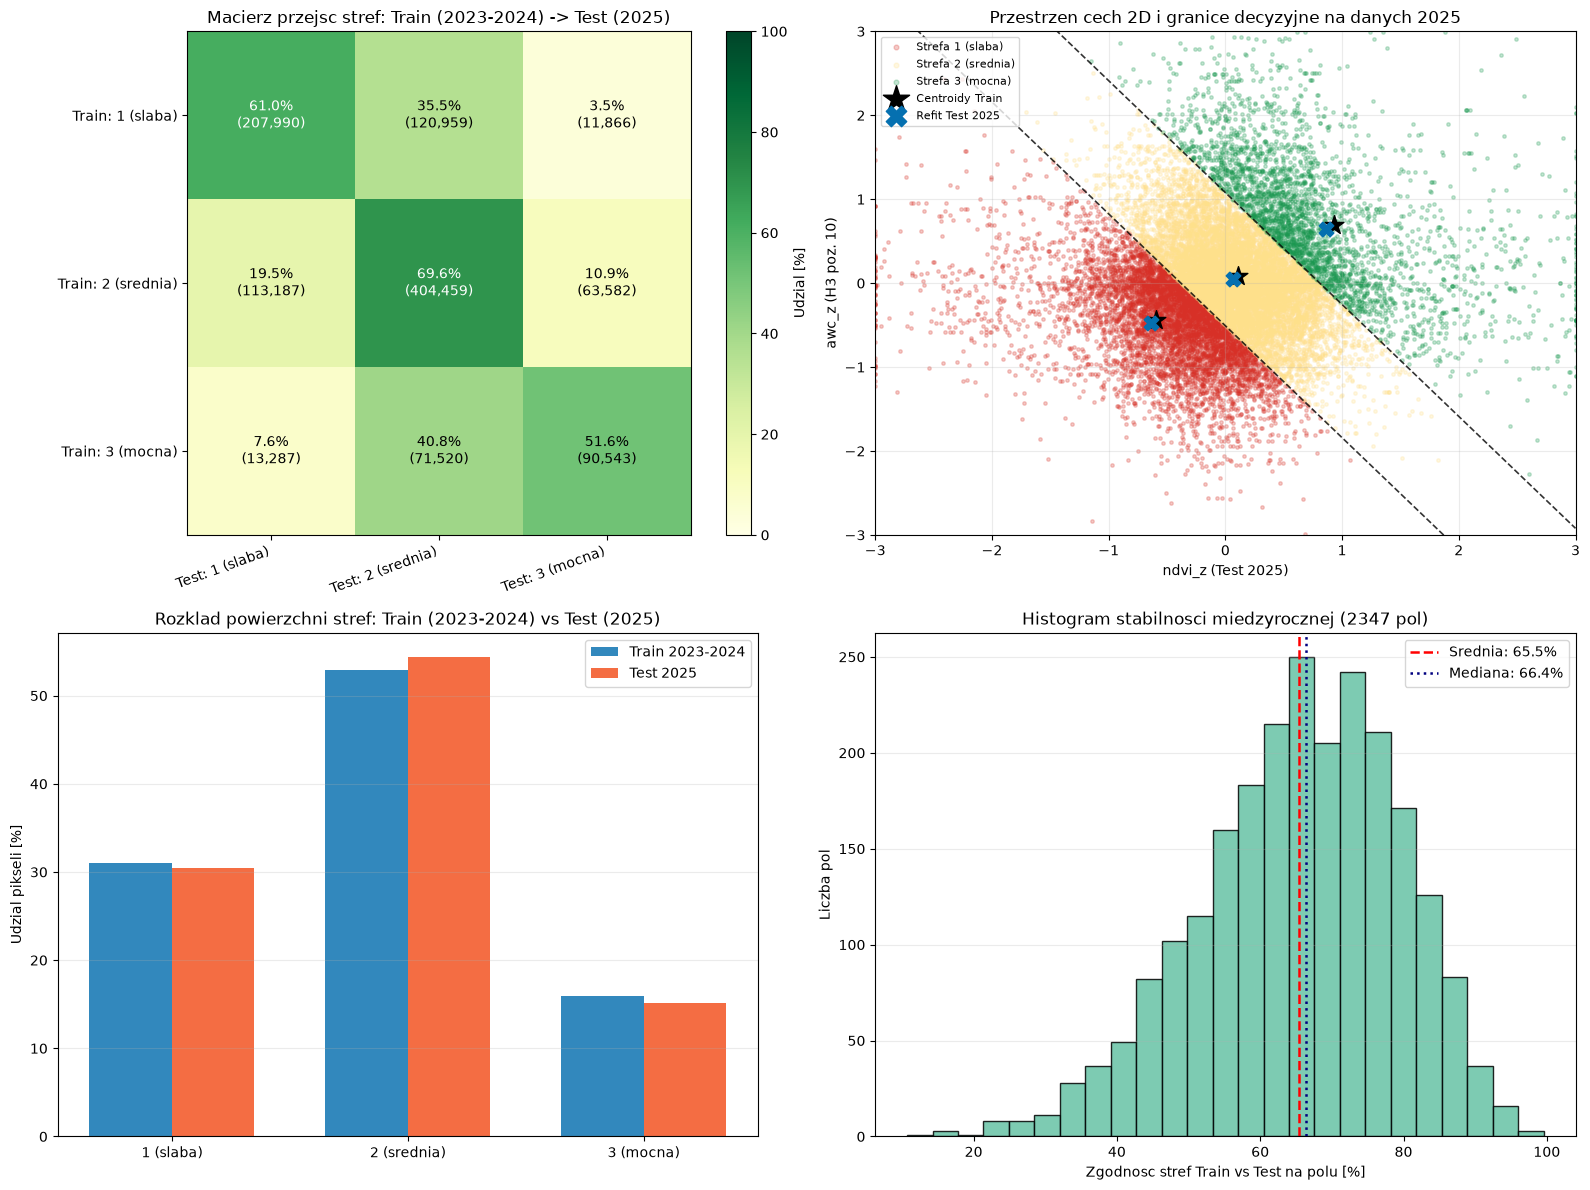

In [7]:
# MODUŁ 3: Wykresy diagnostyczne modelu
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
zone_colors = {1: "#d73027", 2: "#fee08b", 3: "#1a9850"}

# 1. Macierz przejsc stref (Train 2023-2024 -> Test 2025)
cm_pct = comparison["confusion_norm_df"].to_numpy()
cm_cnt = comparison["confusion_counts_df"].to_numpy()
im_cm = axes[0, 0].imshow(cm_pct, cmap="YlGn", vmin=0, vmax=100)
axes[0, 0].set_xticks(range(N_CLUSTERS))
axes[0, 0].set_yticks(range(N_CLUSTERS))
axes[0, 0].set_xticklabels(comparison["confusion_norm_df"].columns, rotation=20, ha="right")
axes[0, 0].set_yticklabels(comparison["confusion_norm_df"].index)
axes[0, 0].set_title("Macierz przejsc stref: Train (2023-2024) -> Test (2025)")
for i in range(N_CLUSTERS):
    for j in range(N_CLUSTERS):
        txt_color = "white" if cm_pct[i, j] > 55 else "black"
        axes[0, 0].text(
            j, i, f"{cm_pct[i, j]:.1f}%\n({cm_cnt[i, j]:,})",
            ha="center", va="center", color=txt_color, fontsize=10,
        )
plt.colorbar(im_cm, ax=axes[0, 0], fraction=0.046, label="Udzial [%]")

# 2. Przestrzen cech 2D [ndvi_z, awc_z] na probce pikseli testowych 2025
sdf = test_eval["sample_df"]
for z in range(1, N_CLUSTERS + 1):
    sub = sdf[sdf["zone_raw"] == z]
    axes[0, 1].scatter(
        sub["ndvi_z"], sub["awc_z"], s=6, alpha=0.25,
        color=zone_colors[z], label=f"Strefa {z} ({ZONE_LABELS_3[z]})",
    )
tr_c = train_eval["model"].cluster_centers_
rf_c = comparison["refit_centers"]
scores = tr_c[:, 0] + AWC_WEIGHT * tr_c[:, 1]
ndvi_line = np.linspace(-3.0, 3.0, 100)
for k in range(N_CLUSTERS - 1):
    thresh = 0.5 * (scores[k] + scores[k + 1])
    awc_line = (thresh - ndvi_line) / AWC_WEIGHT
    axes[0, 1].plot(ndvi_line, awc_line, "k--", linewidth=1.2, alpha=0.8)
axes[0, 1].scatter(tr_c[:, 0], tr_c[:, 1], marker="*", s=200, color="black", zorder=5, label="Centroidy Train")
axes[0, 1].scatter(rf_c[:, 0], rf_c[:, 1], marker="X", s=110, color="#0570b0", zorder=6, label="Refit Test 2025")
axes[0, 1].set_xlim(-3.0, 3.0)
axes[0, 1].set_ylim(-3.0, 3.0)
axes[0, 1].set_xlabel("ndvi_z (Test 2025)")
axes[0, 1].set_ylabel("awc_z (H3 poz. 10)")
axes[0, 1].set_title("Przestrzen cech 2D i granice decyzyjne na danych 2025")
axes[0, 1].legend(loc="upper left", fontsize=8, markerscale=1.4)
axes[0, 1].grid(alpha=0.25)

# 3. Udzial stref (%) w Train vs Test
tr_zs = train_eval["zone_summary_df"].set_index("zone")
te_zs = test_eval["zone_summary_df"].set_index("zone")
x_pos = np.arange(N_CLUSTERS)
width = 0.35
axes[1, 0].bar(x_pos - width / 2, [tr_zs.loc[z, "share_pct"] for z in range(1, N_CLUSTERS + 1)], width, label="Train 2023-2024", color="#3288bd")
axes[1, 0].bar(x_pos + width / 2, [te_zs.loc[z, "share_pct"] for z in range(1, N_CLUSTERS + 1)], width, label="Test 2025", color="#f46d43")
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels([f"{z} ({ZONE_LABELS_3[z]})" for z in range(1, N_CLUSTERS + 1)])
axes[1, 0].set_ylabel("Udzial pikseli [%]")
axes[1, 0].set_title("Rozklad powierzchni stref: Train (2023-2024) vs Test (2025)")
axes[1, 0].legend()
axes[1, 0].grid(axis="y", alpha=0.25)

# 4. Histogram stabilnosci per pole
pf_df = comparison["per_field_stability_df"]
axes[1, 1].hist(pf_df["agreement_pct"], bins=25, color="#66c2a5", edgecolor="black", alpha=0.85)
mean_agr = float(pf_df["agreement_pct"].mean())
med_agr = float(pf_df["agreement_pct"].median())
axes[1, 1].axvline(mean_agr, color="red", linestyle="--", linewidth=1.8, label=f"Srednia: {mean_agr:.1f}%")
axes[1, 1].axvline(med_agr, color="navy", linestyle=":", linewidth=1.8, label=f"Mediana: {med_agr:.1f}%")
axes[1, 1].set_xlabel("Zgodnosc stref Train vs Test na polu [%]")
axes[1, 1].set_ylabel("Liczba pol")
axes[1, 1].set_title(f"Histogram stabilnosci miedzyrocznej ({len(pf_df)} pol)")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

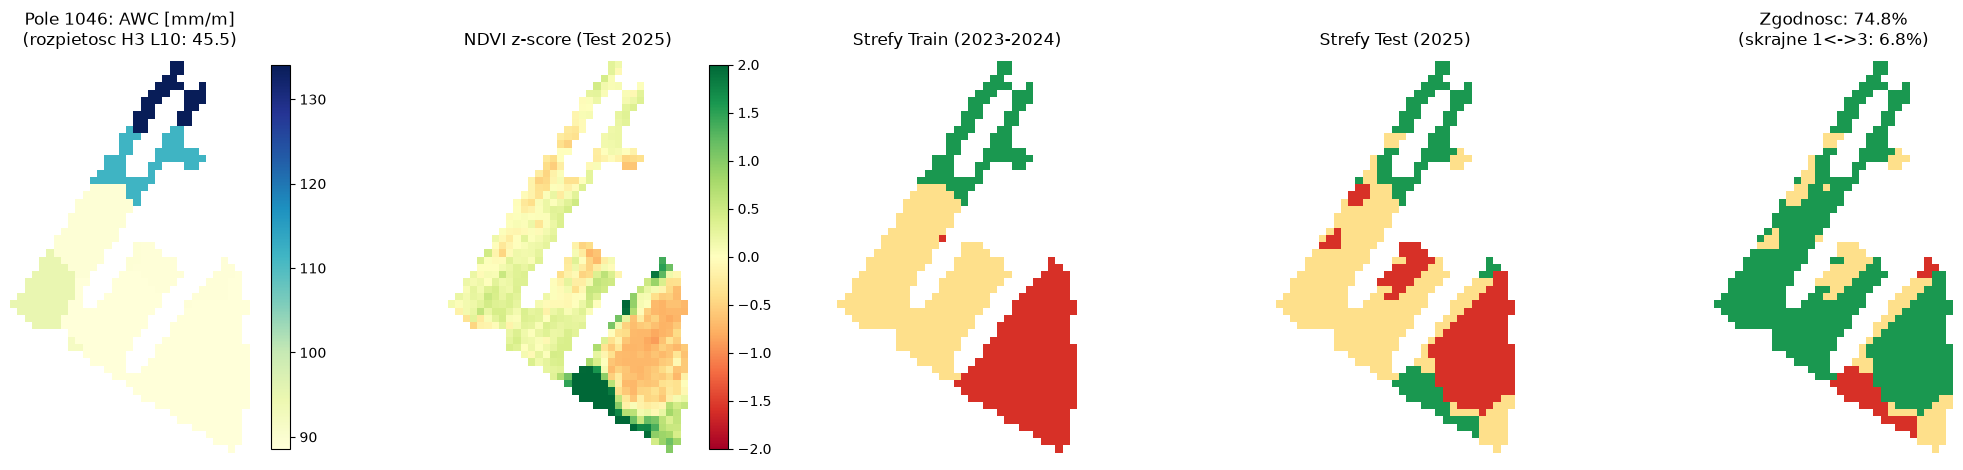

In [8]:
# MODUŁ 4: Porownanie przestrzenne stref Train (2023-2024) vs Test (2025) dla przykladowego pola
pf_candidates = comparison["per_field_stability_df"]
pf_large = pf_candidates[pf_candidates["n_pixels"] >= 200]
candidate_ids = pf_large["field_id"].tolist() if not pf_large.empty else pf_candidates["field_id"].tolist()

best_fid = candidate_ids[0]
best_span = -1.0
for fid in candidate_ids:
    ag = test_eval["field_predictions"][fid].get("awc_grid")
    if ag is None:
        continue
    vals = ag[np.isfinite(ag)]
    if vals.size == 0:
        continue
    span = float(np.max(vals) - np.min(vals))
    if span > best_span:
        best_span = span
        best_fid = fid

tr_z, te_z, tr_ndvi, te_ndvi, awc_grid = align_pair(
    train_eval["field_predictions"][best_fid],
    test_eval["field_predictions"][best_fid],
)
overlap = (tr_z > 0) & (te_z > 0)
diff_code = np.full(tr_z.shape, np.nan, dtype=float)
abs_d = np.abs(tr_z.astype(np.int16) - te_z.astype(np.int16))
diff_code[overlap & (abs_d == 0)] = 1.0  # identyczna strefa
diff_code[overlap & (abs_d == 1)] = 2.0  # przesuniecie o 1 strefe
diff_code[overlap & (abs_d >= 2)] = 3.0  # skrajna zmiana (slaba <-> mocna)

field_row = pf_candidates[pf_candidates["field_id"] == best_fid].iloc[0]
tr_plot = np.where(tr_z > 0, tr_z.astype(float), np.nan)
te_plot = np.where(te_z > 0, te_z.astype(float), np.nan)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))
zone_cmap = ListedColormap(["#d73027", "#fee08b", "#1a9850"])
diff_cmap = ListedColormap(["#1a9850", "#fee08b", "#d73027"])

im0 = axes[0].imshow(awc_grid, cmap="YlGnBu")
axes[0].set_title(f"Pole {best_fid}: AWC [mm/m]\n(rozpietosc H3 L10: {best_span:.1f})")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(te_ndvi, cmap="RdYlGn", vmin=-2, vmax=2)
axes[1].set_title("NDVI z-score (Test 2025)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

axes[2].imshow(tr_plot, cmap=zone_cmap, vmin=1, vmax=3, interpolation="nearest")
axes[2].set_title("Strefy Train (2023-2024)")

axes[3].imshow(te_plot, cmap=zone_cmap, vmin=1, vmax=3, interpolation="nearest")
axes[3].set_title("Strefy Test (2025)")

axes[4].imshow(diff_code, cmap=diff_cmap, vmin=1, vmax=3, interpolation="nearest")
axes[4].set_title(
    f"Zgodnosc: {field_row['agreement_pct']:.1f}%\n"
    f"(skrajne 1<->3: {field_row['extreme_flip_pct']:.1f}%)"
)

for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()